# 01 · Image → Embedding pipeline + GPT-2 caption tokenization
Milestone 1 baseline on the 5000 preprocessed COCO pairs:
1. **Image → embedding** with the CLIP ViT-L/14 vision Transformer.
2. **Caption tokenization** with the GPT-2 tokenizer.
3. **5 image : caption test runs**: images and captions are matched in CLIP's shared embedding space.

In [1]:
import os, json, random, textwrap, torch, matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from transformers import CLIPModel, CLIPProcessor, GPT2TokenizerFast

DATA = os.environ.get('GP1_DATA', '/scratch/hu.zhim/gp1/data')
OUT = '../results/m1_image_caption'; os.makedirs(OUT, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
clip = CLIPModel.from_pretrained('openai/clip-vit-large-patch14').to(device).eval()
proc = CLIPProcessor.from_pretrained('openai/clip-vit-large-patch14')
gpt2_tok = GPT2TokenizerFast.from_pretrained('openai-community/gpt2')
rows = [json.loads(l) for l in open(f'{DATA}/train/metadata.jsonl')]
print(device, '| pairs:', len(rows), '| vision encoder params: %.0fM' % (sum(p.numel() for p in clip.vision_model.parameters()) / 1e6))

cuda | pairs: 5000 | vision encoder params: 303M


## 1. Image → embedding (one image)
The processor resizes to 224×224 and applies CLIP normalization. The ViT splits the image into 14×14-pixel patches (a 16×16 grid): 256 patches + 1 [CLS] token → 257×1024 hidden states. The [CLS] token projected to 768-d is the image embedding.

In [2]:
img = Image.open(f"{DATA}/train/{rows[0]['file_name']}").convert('RGB')
px = proc(images=img, return_tensors='pt')['pixel_values'].to(device)
with torch.no_grad():
    vis = clip.vision_model(pixel_values=px)
    emb = clip.visual_projection(vis.pooler_output)
print('input:', tuple(px.shape), '| patch tokens:', tuple(vis.last_hidden_state.shape), '| embedding:', tuple(emb.shape))

input: (1, 3, 224, 224) | patch tokens: (1, 257, 1024) | embedding: (1, 768)


## 2. Embed all 5000 training images
Saved to disk so later stages can reuse them.

In [3]:
@torch.no_grad()
def embed_images(paths, bs=64):
    out = []
    for i in tqdm(range(0, len(paths), bs)):
        ims = [Image.open(p).convert('RGB') for p in paths[i:i+bs]]
        px = proc(images=ims, return_tensors='pt')['pixel_values'].to(device)
        out.append(clip.get_image_features(pixel_values=px).float().cpu())
    return torch.cat(out)

img_emb = embed_images([f"{DATA}/train/{r['file_name']}" for r in rows])
torch.save({'file_name': [r['file_name'] for r in rows], 'emb': img_emb}, f'{DATA}/train/clip_image_emb.pt')
print('image embeddings:', tuple(img_emb.shape))

  0%|          | 0/79 [00:00<?, ?it/s]

  1%|▏         | 1/79 [00:02<03:51,  2.96s/it]

  3%|▎         | 2/79 [00:05<03:46,  2.94s/it]

  4%|▍         | 3/79 [00:08<03:46,  2.98s/it]

  5%|▌         | 4/79 [00:11<03:42,  2.97s/it]

  6%|▋         | 5/79 [00:14<03:39,  2.97s/it]

... (72 outputs left out)

 99%|█████████▊| 78/79 [03:49<00:02,  2.93s/it]

100%|██████████| 79/79 [03:50<00:00,  2.16s/it]

100%|██████████| 79/79 [03:50<00:00,  2.91s/it]

image embeddings: (5000, 768)


## 3. Tokenize captions with GPT-2
GPT-2 uses byte-level BPE (vocab 50,257). It has no pad token, so the end-of-text token is reused for padding.

A cat sitting on a toilet seat drinking water from a toilet.
[32, 3797, 5586, 319, 257, 16146, 5852, 7722, 1660, 422, 257, 16146, 13]
['A', 'Ġcat', 'Ġsitting', 'Ġon', 'Ġa', 'Ġtoilet', 'Ġseat', 'Ġdrinking', 'Ġwater', 'Ġfrom', 'Ġa', 'Ġtoilet', '.']


vocab: 50257 | tokens per caption: mean 11.9, max 38 | padded: (5000, 38)


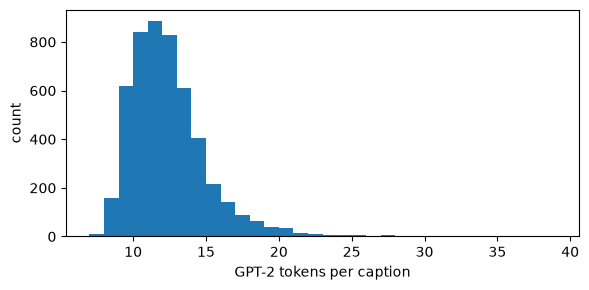

In [4]:
gpt2_tok.pad_token = gpt2_tok.eos_token
cap = rows[0]['text']
ids = gpt2_tok(cap)['input_ids']
print(cap); print(ids); print(gpt2_tok.convert_ids_to_tokens(ids))

lens = [len(gpt2_tok(r['text'])['input_ids']) for r in rows]
MAX_LEN = max(lens)
batch = gpt2_tok([r['text'] for r in rows], padding='max_length', max_length=MAX_LEN, return_tensors='pt')
torch.save({'input_ids': batch['input_ids'], 'attention_mask': batch['attention_mask']}, f'{DATA}/train/gpt2_tokens.pt')
print('vocab:', gpt2_tok.vocab_size, '| tokens per caption: mean %.1f, max %d' % (sum(lens) / len(lens), MAX_LEN), '| padded:', tuple(batch['input_ids'].shape))
plt.figure(figsize=(6, 3)); plt.hist(lens, bins=range(min(lens), MAX_LEN + 2)); plt.xlabel('GPT-2 tokens per caption'); plt.ylabel('count'); plt.tight_layout(); plt.show()

## 4. Five image : caption test runs
For 5 random pairs, every image is scored against all 5 captions by cosine similarity in CLIP space. If the pipeline works, each image's own caption (the diagonal) should score highest.

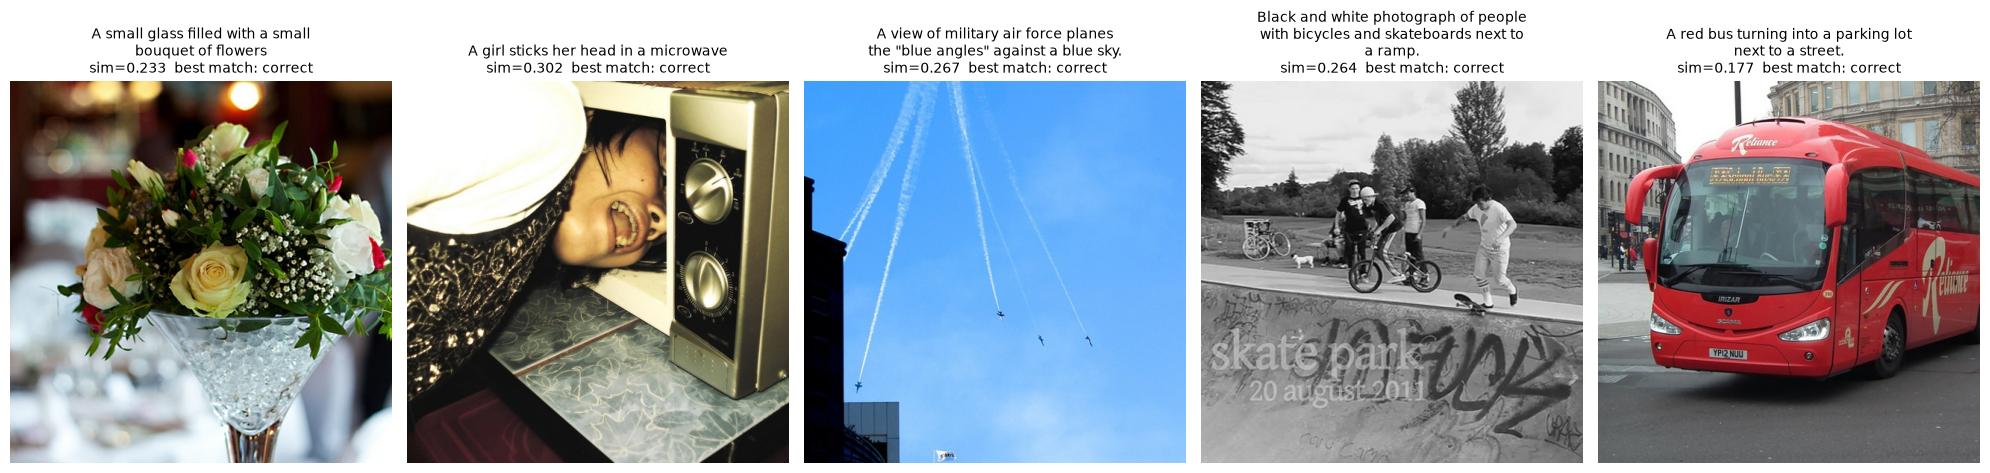

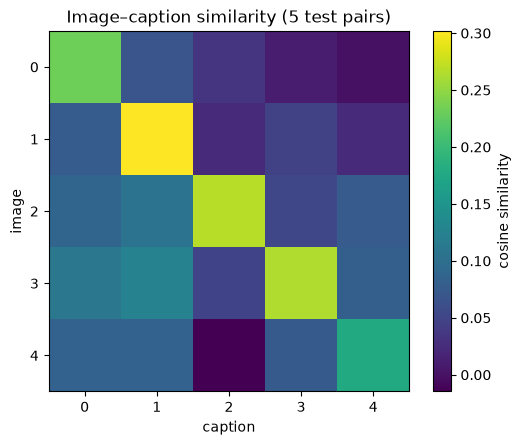

correct matches: 5 / 5


In [5]:
random.seed(0)
idx = random.sample(range(len(rows)), 5)
caps = [rows[i]['text'] for i in idx]
with torch.no_grad():
    t = proc(text=caps, return_tensors='pt', padding=True).to(device)
    txt_emb = clip.get_text_features(**t).float().cpu()
sim = torch.nn.functional.normalize(img_emb[idx], dim=-1) @ torch.nn.functional.normalize(txt_emb, dim=-1).T
pred = sim.argmax(1)

runs = []
fig, ax = plt.subplots(1, 5, figsize=(20, 5.6))
for k, i in enumerate(idx):
    ax[k].imshow(Image.open(f"{DATA}/train/{rows[i]['file_name']}")); ax[k].axis('off')
    ok = pred[k].item() == k
    ax[k].set_title(f"{textwrap.fill(caps[k], 38)}\nsim={sim[k, k]:.3f}  best match: {'correct' if ok else 'wrong'}", fontsize=10)
    runs.append({'file_name': rows[i]['file_name'], 'caption': caps[k], 'gpt2_ids': gpt2_tok(caps[k])['input_ids'],
                 'image_emb_dim': img_emb.shape[1], 'similarity': round(sim[k, k].item(), 4), 'best_match_correct': ok})
plt.tight_layout(); plt.savefig(f'{OUT}/test_runs.png', dpi=110); plt.show()

plt.figure(figsize=(5.5, 4.5)); plt.imshow(sim, cmap='viridis'); plt.colorbar(label='cosine similarity')
plt.xlabel('caption'); plt.ylabel('image'); plt.title('Image–caption similarity (5 test pairs)')
plt.tight_layout(); plt.savefig(f'{OUT}/similarity.png', dpi=110); plt.show()
json.dump(runs, open(f'{OUT}/test_runs.json', 'w'), indent=1)
print('correct matches: %d / 5' % sum(r['best_match_correct'] for r in runs))